# Decision Trees and Support Vector Machines
**Dataset:** UCI Banknote Authentication (1,372 samples, 4 features, 2 classes)



In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# scikit-learn: ONLY for comparison models, toy datasets and metrics
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.datasets import make_moons, make_circles
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 10})
CMAP_BG  = ListedColormap(["#fbb4ae", "#b3cde3"])
CMAP_PTS = ListedColormap(["#e41a1c", "#377eb8"])

## Data loading and a consistent train/test split

In [2]:
COLS = ["variance", "skewness", "curtosis", "entropy", "class"]
DATA_FILE = "data_banknote_authentication.txt"      # local file, same folder as this notebook

def load_banknote(path=DATA_FILE):
    if not os.path.exists(path):
        raise FileNotFoundError(f"'{path}' not found. Keep it in the same folder as this notebook.")
    return pd.read_csv(path, header=None, names=COLS)

df = load_banknote()
print(df.shape); display(df.head()); display(df.describe().T)
print("Class balance:\n", df["class"].value_counts())

(1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


,count,mean,std,min,25%,50%,75%,max
variance,1372.0,0.433735,2.842763,-7.0421,-1.773000,0.49618,2.821475,6.8248
skewness,1372.0,1.922353,5.869047,-13.7731,-1.708200,2.31965,6.814625,12.9516
curtosis,1372.0,1.397627,4.310030,-5.2861,-1.574975,0.61663,3.179250,17.9274
entropy,1372.0,-1.191657,2.101013,-8.5482,-2.413450,-0.58665,0.394810,2.4495
class,1372.0,0.444606,0.497103,0.0000,0.000000,0.00000,1.000000,1.0000


Class balance:
 class
0    762
1    610
Name: count, dtype: int64


In [3]:
FEATURES_ALL = ["variance", "skewness", "curtosis", "entropy"]
FEATURES_2D  = ["variance", "skewness"]

X_all = df[FEATURES_ALL].values.astype(float)
y_all = df["class"].values.astype(int)

def stratified_split(X, y, test_size=0.2, seed=SEED):
    # simple stratified train/test split in NumPy
    rng = np.random.default_rng(seed)
    test_idx = []
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        test_idx.extend(idx[: int(round(len(idx) * test_size))])
    test_idx = np.array(sorted(test_idx))
    mask = np.ones(len(y), bool); mask[test_idx] = False
    return X[mask], X[test_idx], y[mask], y[test_idx]

# ONE split reused everywhere (4-feature arrays; 2-feature arrays are column slices of the same rows)
Xtr4, Xte4, ytr, yte = stratified_split(X_all, y_all)
Xtr2, Xte2 = Xtr4[:, :2], Xte4[:, :2]          # variance, skewness
print("train:", Xtr4.shape, " test:", Xte4.shape, " train class mix:", np.bincount(ytr), " test:", np.bincount(yte))

class StandardScalerScratch:
    # z = (x - mean_train) / std_train  -> statistics come from the TRAINING set only
    def fit(self, X):
        self.mean_ = X.mean(axis=0); self.std_ = X.std(axis=0); self.std_[self.std_ == 0] = 1.0
        return self
    def transform(self, X): return (X - self.mean_) / self.std_
    def fit_transform(self, X): return self.fit(X).transform(X)

def plot_boundary(predict_fn, X, y, ax, title="", n=300, pad=0.5):
    # filled decision regions + data points (2-D only)
    x0, x1 = X[:, 0].min() - pad, X[:, 0].max() + pad
    y0, y1 = X[:, 1].min() - pad, X[:, 1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x0, x1, n), np.linspace(y0, y1, n))
    Z = np.asarray(predict_fn(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.6, cmap=CMAP_BG, levels=[-0.5, 0.5, 1.5])
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=CMAP_PTS, edgecolor="k", s=18, linewidth=0.4)
    ax.set_title(title); ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)

train: (1098, 4)  test: (274, 4)  train class mix: [610 488]  test: [152 122]



# Part A — Decision Tree from scratch

**Impurity measures** (for class proportions $p_k$):
$$G = 1 - \sum_k p_k^2 \qquad\qquad H = -\sum_k p_k \log_2 p_k$$
A split on feature $j$ at threshold $t$ is scored by the weighted child impurity
$\frac{n_L}{n} I_L + \frac{n_R}{n} I_R$; we pick the split with the largest **impurity decrease** (information gain for entropy).
Candidate thresholds are the midpoints between consecutive distinct sorted feature values; cumulative class counts make each feature scan $O(n\log n)$.

In [4]:
# ---------- impurity functions ----------
def _impurity_from_counts(counts, criterion):
    # counts: (..., K) array of class counts -> impurity (...,)
    counts = np.asarray(counts, float)
    tot = counts.sum(axis=-1, keepdims=True)
    p = np.divide(counts, tot, out=np.zeros_like(counts), where=tot > 0)
    if criterion == "gini":
        return 1.0 - (p ** 2).sum(axis=-1)
    if criterion == "entropy":
        logp = np.log2(p, out=np.zeros_like(p), where=p > 0)
        return -(p * logp).sum(axis=-1)
    raise ValueError("criterion must be 'gini' or 'entropy'")

def gini_impurity(y):
    # Gini impurity of a label vector
    return float(_impurity_from_counts(np.bincount(y), "gini"))

def entropy_impurity(y):
    # Shannon entropy (bits) of a label vector
    return float(_impurity_from_counts(np.bincount(y), "entropy"))

print("pure node  :", gini_impurity(np.array([1,1,1,1])), entropy_impurity(np.array([1,1,1,1])))
print("50/50 node :", gini_impurity(np.array([0,0,1,1])), entropy_impurity(np.array([0,0,1,1])))

pure node  : 0.0 -0.0
50/50 node : 0.5 1.0


In [5]:
class Node:
    __slots__ = ("feature", "threshold", "left", "right", "counts", "impurity", "n", "depth", "prediction")
    def __init__(self, counts, impurity, depth):
        self.feature = None; self.threshold = None; self.left = None; self.right = None
        self.counts = counts; self.impurity = impurity; self.n = int(counts.sum()); self.depth = depth
        self.prediction = int(np.argmax(counts))
    @property
    def is_leaf(self): return self.left is None


class DecisionTreeScratch:
    # CART-style binary classification tree (NumPy only).
    # Stopping rules: max_depth, min_samples_split, min_samples_leaf, min_impurity_decrease, pure node.
    def __init__(self, criterion="gini", max_depth=None, min_samples_split=2,
                 min_samples_leaf=1, min_impurity_decrease=0.0):
        self.criterion = criterion; self.max_depth = max_depth
        self.min_samples_split = min_samples_split; self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease

    # ----- training -----
    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y)
        self.classes_, y_idx = np.unique(y, return_inverse=True)
        self.n_classes_, self.n_features_ = len(self.classes_), X.shape[1]
        self.root_ = self._grow(X, y_idx, depth=0)
        return self

    def _best_split(self, X, y, parent_imp):
        n, d = X.shape; K = self.n_classes_
        onehot = np.eye(K)[y]; total = onehot.sum(axis=0)
        best = (None, None, 0.0)                                  # feature, threshold, gain
        for j in range(d):
            order = np.argsort(X[:, j], kind="stable")
            xs, oh = X[order, j], onehot[order]
            left = np.cumsum(oh, axis=0)[:-1]                     # counts for every possible cut
            right = total - left
            nl = np.arange(1, n); nr = n - nl
            valid = (xs[1:] > xs[:-1]) & (nl >= self.min_samples_leaf) & (nr >= self.min_samples_leaf)
            if not valid.any(): continue
            w_imp = (nl * _impurity_from_counts(left, self.criterion) +
                     nr * _impurity_from_counts(right, self.criterion)) / n
            w_imp = np.where(valid, w_imp, np.inf)
            i = int(np.argmin(w_imp)); gain = parent_imp - w_imp[i]
            if gain > best[2] + 1e-12:
                best = (j, (xs[i] + xs[i + 1]) / 2.0, gain)
        return best

    def _grow(self, X, y, depth):
        counts = np.bincount(y, minlength=self.n_classes_).astype(float)
        node = Node(counts, float(_impurity_from_counts(counts, self.criterion)), depth)
        # stopping rules
        if (node.impurity == 0.0 or node.n < self.min_samples_split or
                (self.max_depth is not None and depth >= self.max_depth)):
            return node
        j, t, gain = self._best_split(X, y, node.impurity)
        if j is None or gain < self.min_impurity_decrease:
            return node
        mask = X[:, j] <= t
        node.feature, node.threshold = j, t
        node.left = self._grow(X[mask], y[mask], depth + 1)
        node.right = self._grow(X[~mask], y[~mask], depth + 1)
        return node

    # ----- prediction (vectorised: route index sets down the tree) -----
    def predict(self, X):
        X = np.asarray(X, float); out = np.empty(len(X), dtype=int)
        def route(node, idx):
            if node.is_leaf or len(idx) == 0:
                out[idx] = node.prediction; return
            m = X[idx, node.feature] <= node.threshold
            route(node.left, idx[m]); route(node.right, idx[~m])
        route(self.root_, np.arange(len(X)))
        return self.classes_[out]

    # ----- introspection -----
    def get_depth(self):
        def d(n): return 0 if n.is_leaf else 1 + max(d(n.left), d(n.right))
        return d(self.root_)
    def get_n_leaves(self):
        def c(n): return 1 if n.is_leaf else c(n.left) + c(n.right)
        return c(self.root_)

    def export_rules(self, feature_names=None):
        fn = feature_names or [f"x{i}" for i in range(self.n_features_)]
        lines = []
        def rec(node, ind):
            pad = "|   " * ind
            if node.is_leaf:
                lines.append(f"{pad}|--- class {self.classes_[node.prediction]}  "
                             f"(n={node.n}, counts={node.counts.astype(int).tolist()}, {self.criterion}={node.impurity:.3f})")
                return
            lines.append(f"{pad}|--- {fn[node.feature]} <= {node.threshold:.4f}")
            rec(node.left, ind + 1)
            lines.append(f"{pad}|--- {fn[node.feature]} >  {node.threshold:.4f}")
            rec(node.right, ind + 1)
        rec(self.root_, 0)
        return "\n".join(lines)


def plot_tree_scratch(tree, feature_names, class_names=("class 0", "class 1"), ax=None, fontsize=8):
    # draw the learned manual tree: internal nodes show the split rule, leaves show the predicted class
    pos, counter = {}, [0]
    def layout(node):
        if node.is_leaf:
            x = counter[0]; counter[0] += 1
        else:
            x = (layout(node.left) + layout(node.right)) / 2.0
        pos[id(node)] = (x, -node.depth); return x
    layout(tree.root_)
    if ax is None:
        _, ax = plt.subplots(figsize=(max(8, 1.6 * counter[0]), 2.2 * (tree.get_depth() + 1)))
    def draw(node):
        x, y = pos[id(node)]
        if node.is_leaf:
            txt = f"{class_names[node.prediction]}\nn={node.n}\n{node.counts.astype(int).tolist()}"
            col = "#fbb4ae" if node.prediction == 0 else "#b3cde3"
        else:
            txt = f"{feature_names[node.feature]} <= {node.threshold:.2f}\n{tree.criterion}={node.impurity:.3f}\nn={node.n}"
            col = "#f2f2f2"
            for child, lab in ((node.left, "True"), (node.right, "False")):
                cx, cy = pos[id(child)]
                ax.plot([x, cx], [y, cy], "-", color="gray", zorder=1)
                ax.text((x + cx) / 2, (y + cy) / 2, lab, fontsize=fontsize - 1, color="dimgray", ha="center")
                draw(child)
        ax.text(x, y, txt, ha="center", va="center", fontsize=fontsize, zorder=3,
                bbox=dict(boxstyle="round,pad=0.3", fc=col, ec="k"))
    draw(tree.root_)
    ax.set_axis_off(); ax.set_ylim(-tree.get_depth() - 0.5, 0.5); ax.set_xlim(-0.7, counter[0] - 0.3)
    return ax

### manual vs scikit-learn tree (variance & skewness only)

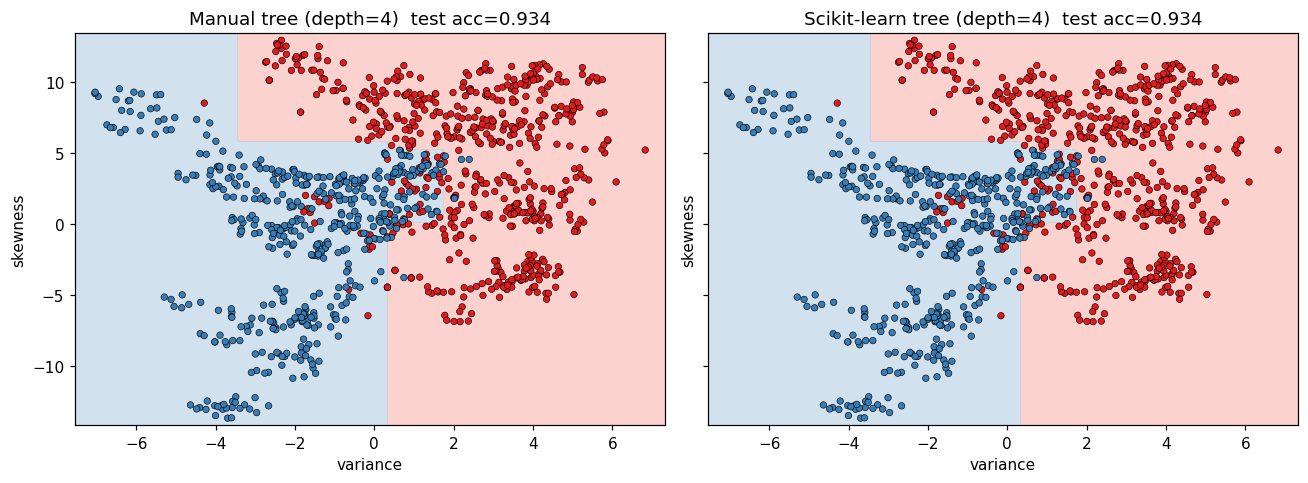

Prediction agreement on test set: 1.0


In [6]:
DEPTH_DEMO = 4
man2 = DecisionTreeScratch(criterion="gini", max_depth=DEPTH_DEMO).fit(Xtr2, ytr)
skl2 = DecisionTreeClassifier(criterion="gini", max_depth=DEPTH_DEMO, random_state=SEED).fit(Xtr2, ytr)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
plot_boundary(man2.predict, Xtr2, ytr, axes[0], f"Manual tree (depth={DEPTH_DEMO})  test acc={accuracy_score(yte, man2.predict(Xte2)):.3f}")
plot_boundary(skl2.predict, Xtr2, ytr, axes[1], f"Scikit-learn tree (depth={DEPTH_DEMO})  test acc={accuracy_score(yte, skl2.predict(Xte2)):.3f}")
for a in axes: a.set_xlabel("variance"); a.set_ylabel("skewness")
plt.tight_layout(); plt.show()
print("Prediction agreement on test set:", np.mean(man2.predict(Xte2) == skl2.predict(Xte2)))

### Learned manual tree and its split rules

|--- variance <= 0.3202
|   |--- skewness <= 5.8654
|   |   |--- variance <= -1.7820
|   |   |   |--- skewness <= 1.7724
|   |   |   |   |--- class 1  (n=150, counts=[0, 150], gini=0.000)
|   |   |   |--- skewness >  1.7724
|   |   |   |   |--- class 1  (n=62, counts=[1, 61], gini=0.032)
|   |   |--- variance >  -1.7820
|   |   |   |--- variance <= -1.7747
|   |   |   |   |--- class 0  (n=1, counts=[1, 0], gini=0.000)
|   |   |   |--- variance >  -1.7747
|   |   |   |   |--- class 1  (n=197, counts=[18, 179], gini=0.166)
|   |--- skewness >  5.8654
|   |   |--- variance <= -3.4449
|   |   |   |--- variance <= -4.3819
|   |   |   |   |--- class 1  (n=29, counts=[0, 29], gini=0.000)
|   |   |   |--- variance >  -4.3819
|   |   |   |   |--- class 1  (n=3, counts=[1, 2], gini=0.444)
|   |   |--- variance >  -3.4449
|   |   |   |--- class 0  (n=77, counts=[77, 0], gini=0.000)
|--- variance >  0.3202
|   |--- variance <= 1.7439
|   |   |--- skewness <= 5.2736
|   |   |   |--- skewness <= 0.0

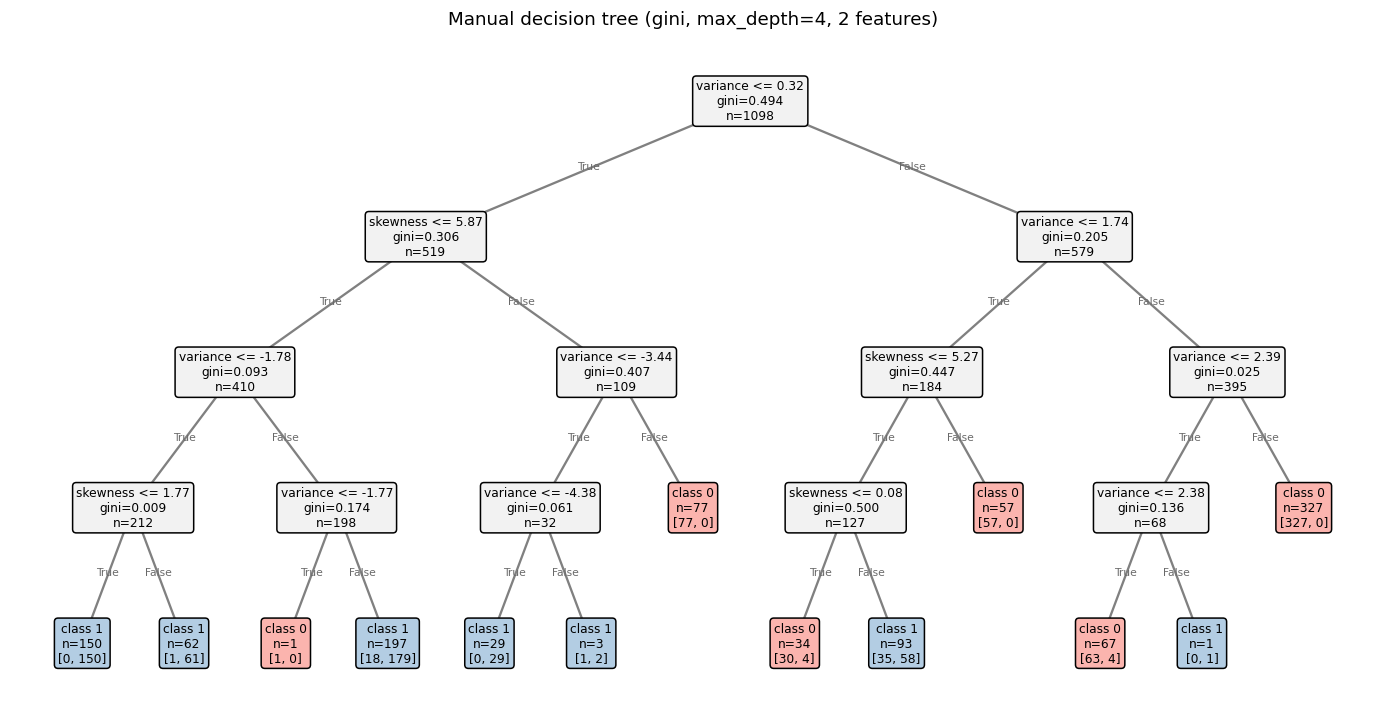

In [7]:
print(man2.export_rules(FEATURES_2D))
fig, ax = plt.subplots(figsize=(16, 8))
plot_tree_scratch(man2, FEATURES_2D, ax=ax)
ax.set_title(f"Manual decision tree (gini, max_depth={DEPTH_DEMO}, 2 features)")
plt.show()

### Criterion and maximum-depth study

,criterion,max_depth,manual_train,manual_test,sklearn_train,sklearn_test,agreement,manual_leaves,sklearn_leaves
0,gini,1,0.8497,0.8686,0.8497,0.8686,1.0000,2,2
1,gini,2,0.8925,0.9088,0.8925,0.9088,1.0000,4,4
2,gini,3,0.9199,0.9380,0.9199,0.9380,1.0000,8,8
3,gini,4,0.9426,0.9343,0.9426,0.9343,1.0000,13,13
4,gini,5,0.9463,0.9380,0.9463,0.9416,0.9964,19,19
5,gini,6,0.9590,0.9380,0.9590,0.9380,1.0000,24,24
6,gini,8,0.9763,0.9416,0.9781,0.9453,0.9964,41,42
7,gini,10,0.9973,0.9307,0.9973,0.9343,0.9964,67,67
8,gini,None,1.0000,0.9307,1.0000,0.9343,0.9964,71,71
9,entropy,1,0.8406,0.8358,0.8406,0.8358,1.0000,2,2


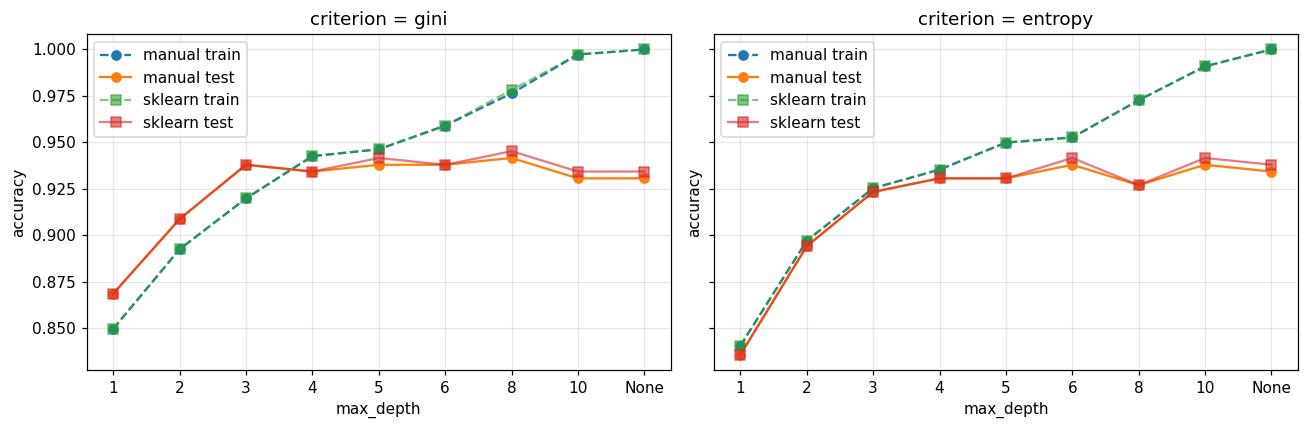

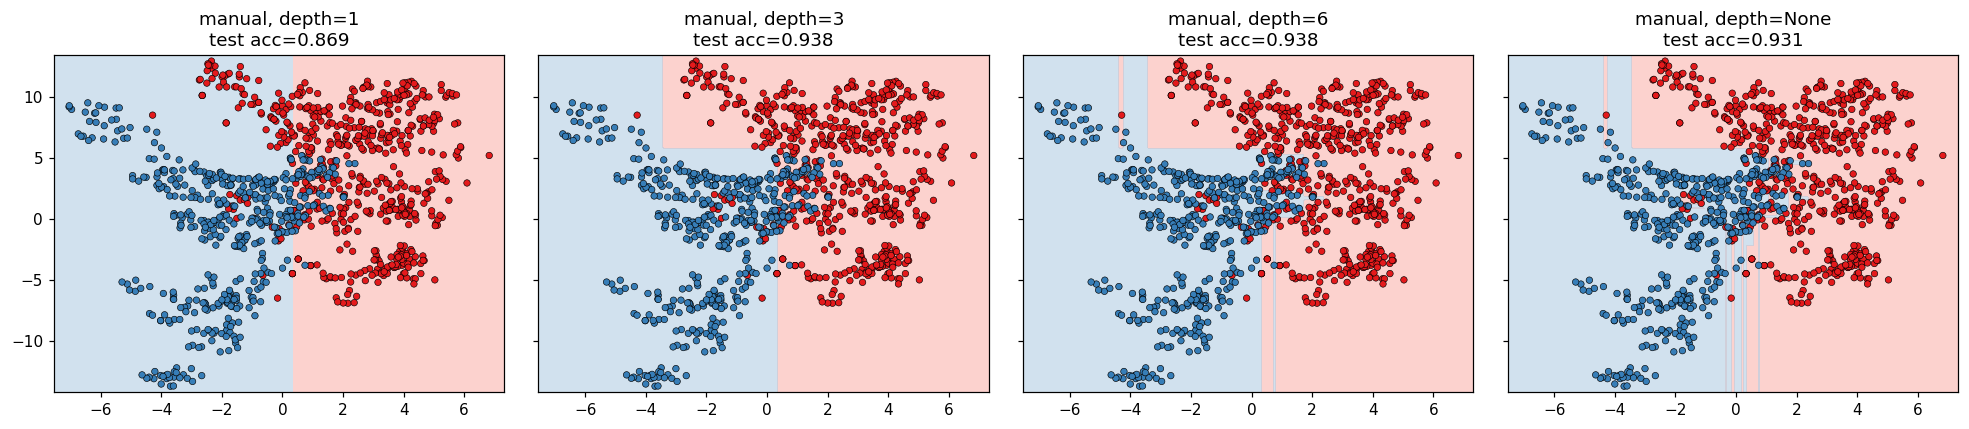

In [8]:
rows = []
for crit in ["gini", "entropy"]:
    for depth in [1, 2, 3, 4, 5, 6, 8, 10, None]:
        m = DecisionTreeScratch(criterion=crit, max_depth=depth).fit(Xtr2, ytr)
        s = DecisionTreeClassifier(criterion=crit, max_depth=depth, random_state=SEED).fit(Xtr2, ytr)
        pm, ps = m.predict(Xte2), s.predict(Xte2)
        rows.append(dict(criterion=crit, max_depth=str(depth),
                         manual_train=accuracy_score(ytr, m.predict(Xtr2)), manual_test=accuracy_score(yte, pm),
                         sklearn_train=accuracy_score(ytr, s.predict(Xtr2)), sklearn_test=accuracy_score(yte, ps),
                         agreement=np.mean(pm == ps), manual_leaves=m.get_n_leaves(), sklearn_leaves=s.get_n_leaves()))
res_tree = pd.DataFrame(rows)
display(res_tree.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, crit in zip(axes, ["gini", "entropy"]):
    r = res_tree[res_tree.criterion == crit]
    ax.plot(r.max_depth, r.manual_train, "o--", label="manual train"); ax.plot(r.max_depth, r.manual_test, "o-", label="manual test")
    ax.plot(r.max_depth, r.sklearn_train, "s--", label="sklearn train", alpha=.6); ax.plot(r.max_depth, r.sklearn_test, "s-", label="sklearn test", alpha=.6)
    ax.set_title(f"criterion = {crit}"); ax.set_xlabel("max_depth"); ax.set_ylabel("accuracy"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

# boundaries for different depths (gini, manual)
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharex=True, sharey=True)
for ax, d in zip(axes, [1, 3, 6, None]):
    m = DecisionTreeScratch("gini", max_depth=d).fit(Xtr2, ytr)
    plot_boundary(m.predict, Xtr2, ytr, ax, f"manual, depth={d}\ntest acc={accuracy_score(yte, m.predict(Xte2)):.3f}")
plt.tight_layout(); plt.show()


# Part B — Linear soft-margin SVM from scratch

Labels are mapped to $y\in\{-1,+1\}$ and features are standardised with **training-set** mean/std.
Primal objective (equivalent to scikit-learn's $\tfrac12\|w\|^2 + C\sum_i \max(0,1-y_i f(x_i))$ divided by $nC$):
$$J(w,b)=\frac{\lambda}{2}\|w\|^2+\frac1n\sum_{i=1}^n \max\bigl(0,\,1-y_i(w^\top x_i+b)\bigr),\qquad \lambda=\frac{1}{C\,n}$$
Subgradient (violators $V=\{i: y_i f(x_i)<1\}$):
$$\nabla_w J=\lambda w-\frac1n\sum_{i\in V} y_i x_i,\qquad \nabla_b J=-\frac1n\sum_{i\in V} y_i$$
We run full-batch subgradient descent with learning rate $\eta_t=\eta_0/(1+\text{decay}\cdot t)$. The bias is not regularised.

In [9]:
class LinearSVMScratch:
    # Linear soft-margin SVM, hinge loss, full-batch subgradient descent (NumPy only). y must be in {-1,+1}.
    def __init__(self, C=1.0, lr=0.5, n_iters=1000, lr_decay=0.01):
        self.C, self.lr, self.n_iters, self.lr_decay = C, lr, n_iters, lr_decay

    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float)
        n, d = X.shape; lam = 1.0 / (self.C * n)
        self.w_, self.b_ = np.zeros(d), 0.0
        self.loss_history_ = []
        for t in range(self.n_iters):
            eta = self.lr / (1.0 + self.lr_decay * t)
            viol = y * (X @ self.w_ + self.b_) < 1
            grad_w = lam * self.w_ - (y[viol, None] * X[viol]).sum(axis=0) / n
            grad_b = -y[viol].sum() / n
            self.w_ -= eta * grad_w; self.b_ -= eta * grad_b
            hinge = np.maximum(0.0, 1.0 - y * (X @ self.w_ + self.b_))
            self.loss_history_.append(0.5 * lam * self.w_ @ self.w_ + hinge.mean())
        return self

    def decision_function(self, X): return np.asarray(X, float) @ self.w_ + self.b_
    def predict(self, X): return np.where(self.decision_function(X) >= 0, 1, -1)

to_pm1 = lambda y: 2 * np.asarray(y) - 1          # {0,1} -> {-1,+1}
from_pm1 = lambda y: (np.asarray(y) + 1) // 2      # {-1,+1} -> {0,1}

# scale with TRAINING statistics only
sc2 = StandardScalerScratch().fit(Xtr2)
Xtr2s, Xte2s = sc2.transform(Xtr2), sc2.transform(Xte2)
ytr_pm, yte_pm = to_pm1(ytr), to_pm1(yte)
print("train mean/std after scaling:", Xtr2s.mean(0).round(6), Xtr2s.std(0).round(6))

train mean/std after scaling: [ 0. -0.] [1. 1.]


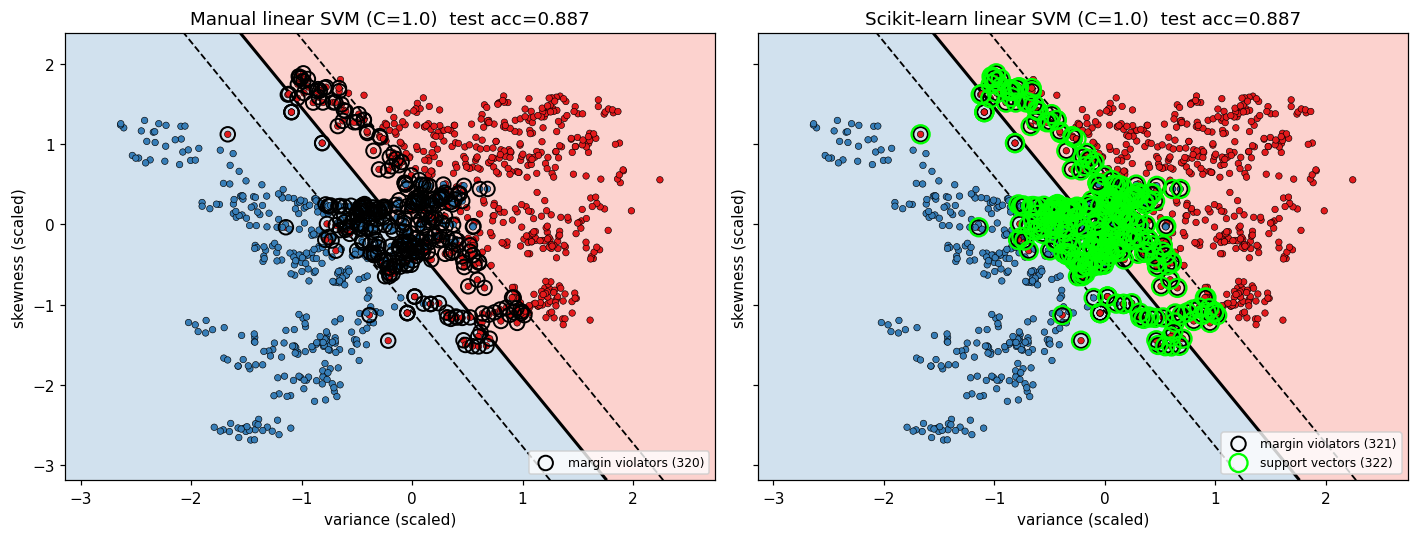

Manual : w = [-1.9546 -1.1639]  b = -0.2641  margin width 2/||w|| = 0.8792
sklearn: w = [-1.9544 -1.1638]  b = -0.2641  margin width 2/||w|| = 0.8792
Prediction agreement (test): 1.0


In [10]:
C_DEMO = 1.0
svm_m = LinearSVMScratch(C=C_DEMO, lr=0.5, n_iters=1000, lr_decay=0.01).fit(Xtr2s, ytr_pm)
svm_s = SVC(kernel="linear", C=C_DEMO).fit(Xtr2s, ytr_pm)

def plot_margin(f_dec, X, y_pm, ax, title, support=None):
    # separating line f=0, margins f=+/-1, margin violators (y*f<1) ringed in black
    pad = 0.5
    x0, x1, y0, y1 = X[:, 0].min()-pad, X[:, 0].max()+pad, X[:, 1].min()-pad, X[:, 1].max()+pad
    xx, yy = np.meshgrid(np.linspace(x0, x1, 300), np.linspace(y0, y1, 300))
    Z = f_dec(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-1e9, 0, 1e9], cmap=CMAP_BG, alpha=0.6)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[1.2, 2, 1.2])
    ax.scatter(X[:, 0], X[:, 1], c=(y_pm + 1) // 2, cmap=CMAP_PTS, edgecolor="k", s=18, linewidth=0.4, zorder=3)
    viol = y_pm * f_dec(X) < 1
    ax.scatter(X[viol, 0], X[viol, 1], s=90, facecolors="none", edgecolors="k", linewidths=1.3, zorder=4, label=f"margin violators ({viol.sum()})")
    if support is not None:
        ax.scatter(support[:, 0], support[:, 1], s=140, facecolors="none", edgecolors="lime", linewidths=1.5, zorder=4, label=f"support vectors ({len(support)})")
    ax.set_title(title); ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.legend(loc="lower right", fontsize=8)
    ax.set_xlabel("variance (scaled)"); ax.set_ylabel("skewness (scaled)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
plot_margin(svm_m.decision_function, Xtr2s, ytr_pm, axes[0],
            f"Manual linear SVM (C={C_DEMO})  test acc={accuracy_score(yte_pm, svm_m.predict(Xte2s)):.3f}")
plot_margin(svm_s.decision_function, Xtr2s, ytr_pm, axes[1],
            f"Scikit-learn linear SVM (C={C_DEMO})  test acc={accuracy_score(yte_pm, svm_s.predict(Xte2s)):.3f}", support=svm_s.support_vectors_)
plt.tight_layout(); plt.show()

print("Manual : w =", svm_m.w_.round(4), " b =", round(svm_m.b_, 4), " margin width 2/||w|| =", round(2/np.linalg.norm(svm_m.w_), 4))
print("sklearn: w =", svm_s.coef_[0].round(4), " b =", round(svm_s.intercept_[0], 4), " margin width 2/||w|| =", round(2/np.linalg.norm(svm_s.coef_[0]), 4))
print("Prediction agreement (test):", np.mean(svm_m.predict(Xte2s) == svm_s.predict(Xte2s)))

### Effect of regularisation $C$

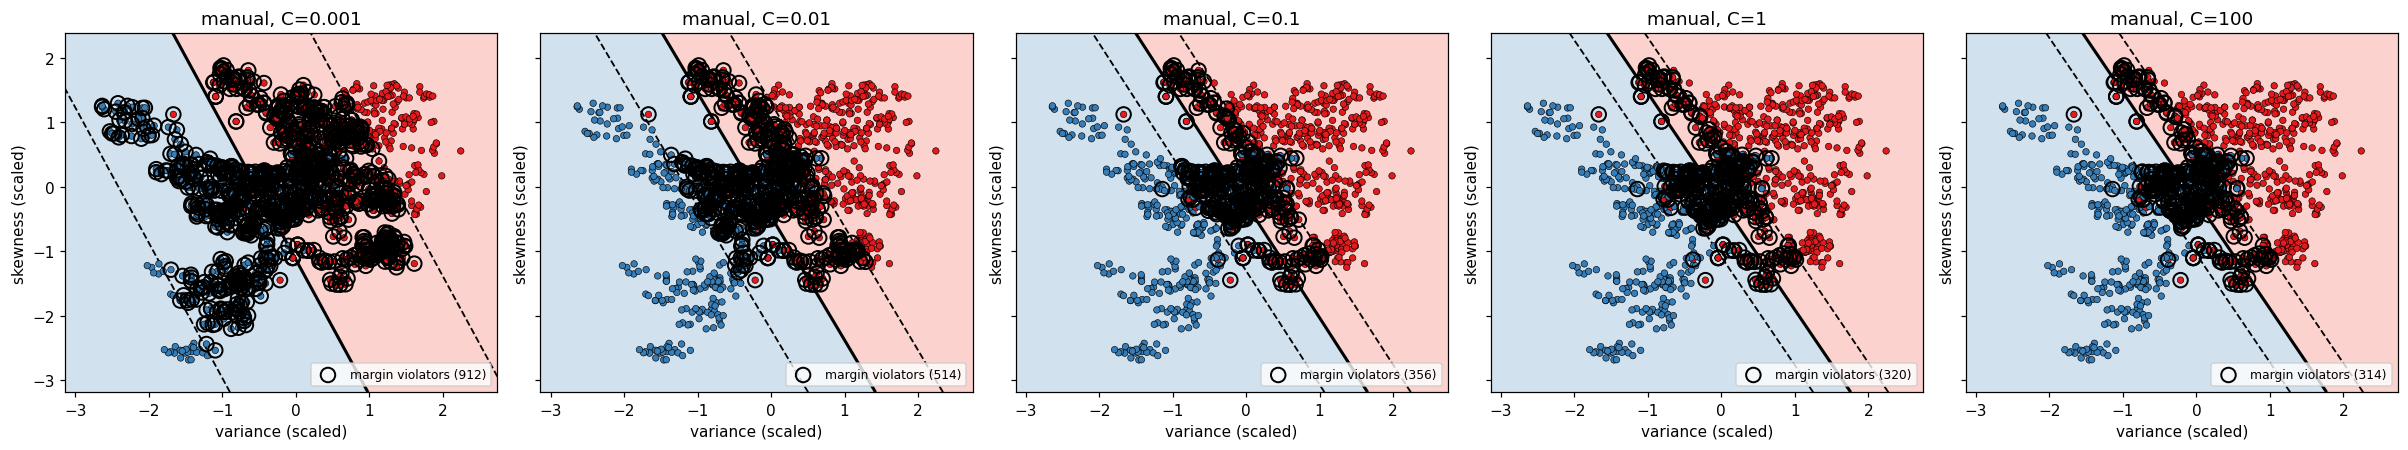

,C,manual_train,manual_test,sklearn_test,violators,margin_width,sklearn_margin_width,cos_sim_w
0,0.001,0.8488,0.8723,0.8723,912,3.3878,3.3879,1.0
1,0.010,0.8743,0.8942,0.8942,514,1.6266,1.6266,1.0
2,0.100,0.8770,0.8905,0.8905,356,1.0217,1.0217,1.0
3,1.000,0.8734,0.8869,0.8869,320,0.8792,0.8792,1.0
4,100.000,0.8743,0.8905,0.8905,314,0.8526,0.8525,1.0


In [11]:
rows = []
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2), sharex=True, sharey=True)
for ax, C in zip(axes, [0.001, 0.01, 0.1, 1, 100]):
    m = LinearSVMScratch(C=C, lr=0.5, n_iters=3000, lr_decay=0.01).fit(Xtr2s, ytr_pm)
    s = SVC(kernel="linear", C=C).fit(Xtr2s, ytr_pm)
    cos = m.w_ @ s.coef_[0] / (np.linalg.norm(m.w_) * np.linalg.norm(s.coef_[0]))
    rows.append(dict(C=C, manual_train=accuracy_score(ytr_pm, m.predict(Xtr2s)), manual_test=accuracy_score(yte_pm, m.predict(Xte2s)),
                     sklearn_test=accuracy_score(yte_pm, s.predict(Xte2s)), violators=int((ytr_pm * m.decision_function(Xtr2s) < 1).sum()),
                     margin_width=2/np.linalg.norm(m.w_), sklearn_margin_width=2/np.linalg.norm(s.coef_[0]), cos_sim_w=cos))
    plot_margin(m.decision_function, Xtr2s, ytr_pm, ax, f"manual, C={C}")
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).round(4))

### Effect of learning rate and number of iterations

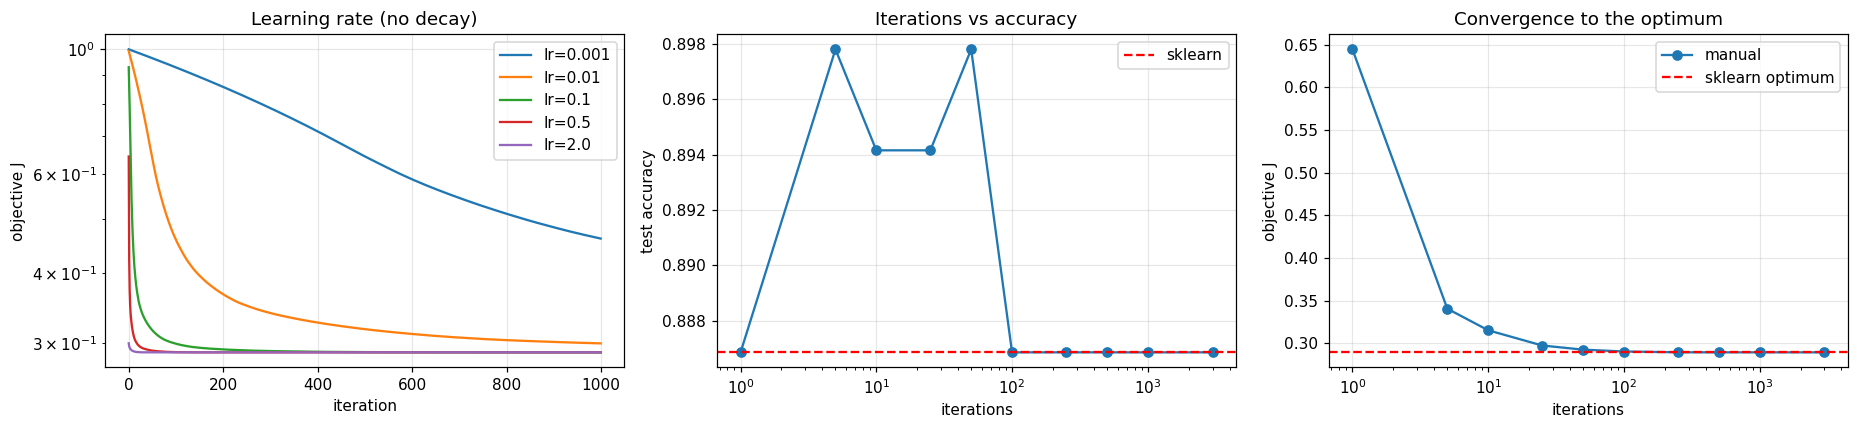

Objective at sklearn solution: 0.28924   manual (1000 it): 0.28924


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
# (a) learning rate -> loss curves
for lr in [0.001, 0.01, 0.1, 0.5, 2.0]:
    m = LinearSVMScratch(C=1, lr=lr, n_iters=1000, lr_decay=0.0).fit(Xtr2s, ytr_pm)
    axes[0].plot(m.loss_history_, label=f"lr={lr}")
axes[0].set_yscale("log"); axes[0].set_xlabel("iteration"); axes[0].set_ylabel("objective J"); axes[0].set_title("Learning rate (no decay)"); axes[0].legend(); axes[0].grid(alpha=.3)

# (b) iterations -> accuracy and loss
iters_list = [1, 5, 10, 25, 50, 100, 250, 500, 1000, 3000]
accs, losses = [], []
for it in iters_list:
    m = LinearSVMScratch(C=1, lr=0.5, n_iters=it, lr_decay=0.01).fit(Xtr2s, ytr_pm)
    accs.append(accuracy_score(yte_pm, m.predict(Xte2s))); losses.append(m.loss_history_[-1])
axes[1].semilogx(iters_list, accs, "o-"); axes[1].axhline(accuracy_score(yte_pm, svm_s.predict(Xte2s)), color="r", ls="--", label="sklearn")
axes[1].set_xlabel("iterations"); axes[1].set_ylabel("test accuracy"); axes[1].set_title("Iterations vs accuracy"); axes[1].legend(); axes[1].grid(alpha=.3)

# (c) final objective vs sklearn's optimum objective
lam = 1 / (1 * len(ytr_pm))
f = svm_s.decision_function(Xtr2s)
J_skl = 0.5 * lam * (svm_s.coef_[0] @ svm_s.coef_[0]) + np.maximum(0, 1 - ytr_pm * f).mean()
axes[2].semilogx(iters_list, losses, "o-", label="manual"); axes[2].axhline(J_skl, color="r", ls="--", label="sklearn optimum")
axes[2].set_xlabel("iterations"); axes[2].set_ylabel("objective J"); axes[2].set_title("Convergence to the optimum"); axes[2].legend(); axes[2].grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"Objective at sklearn solution: {J_skl:.5f}   manual (1000 it): {LinearSVMScratch(C=1,lr=0.5,n_iters=1000,lr_decay=0.01).fit(Xtr2s,ytr_pm).loss_history_[-1]:.5f}")


# Part C — Kernel SVM and nonlinear boundaries
When classes are not linearly separable in the input space, a kernel $k(x,x')=\phi(x)^\top\phi(x')$ lets the SVM fit a **linear** separator in an (implicit) higher-dimensional feature space,
which appears as a **curved** boundary in the original space. Polynomial: $(\gamma x^\top x' + r)^d$; RBF: $\exp(-\gamma\|x-x'\|^2)$ (local, infinite-dimensional features).

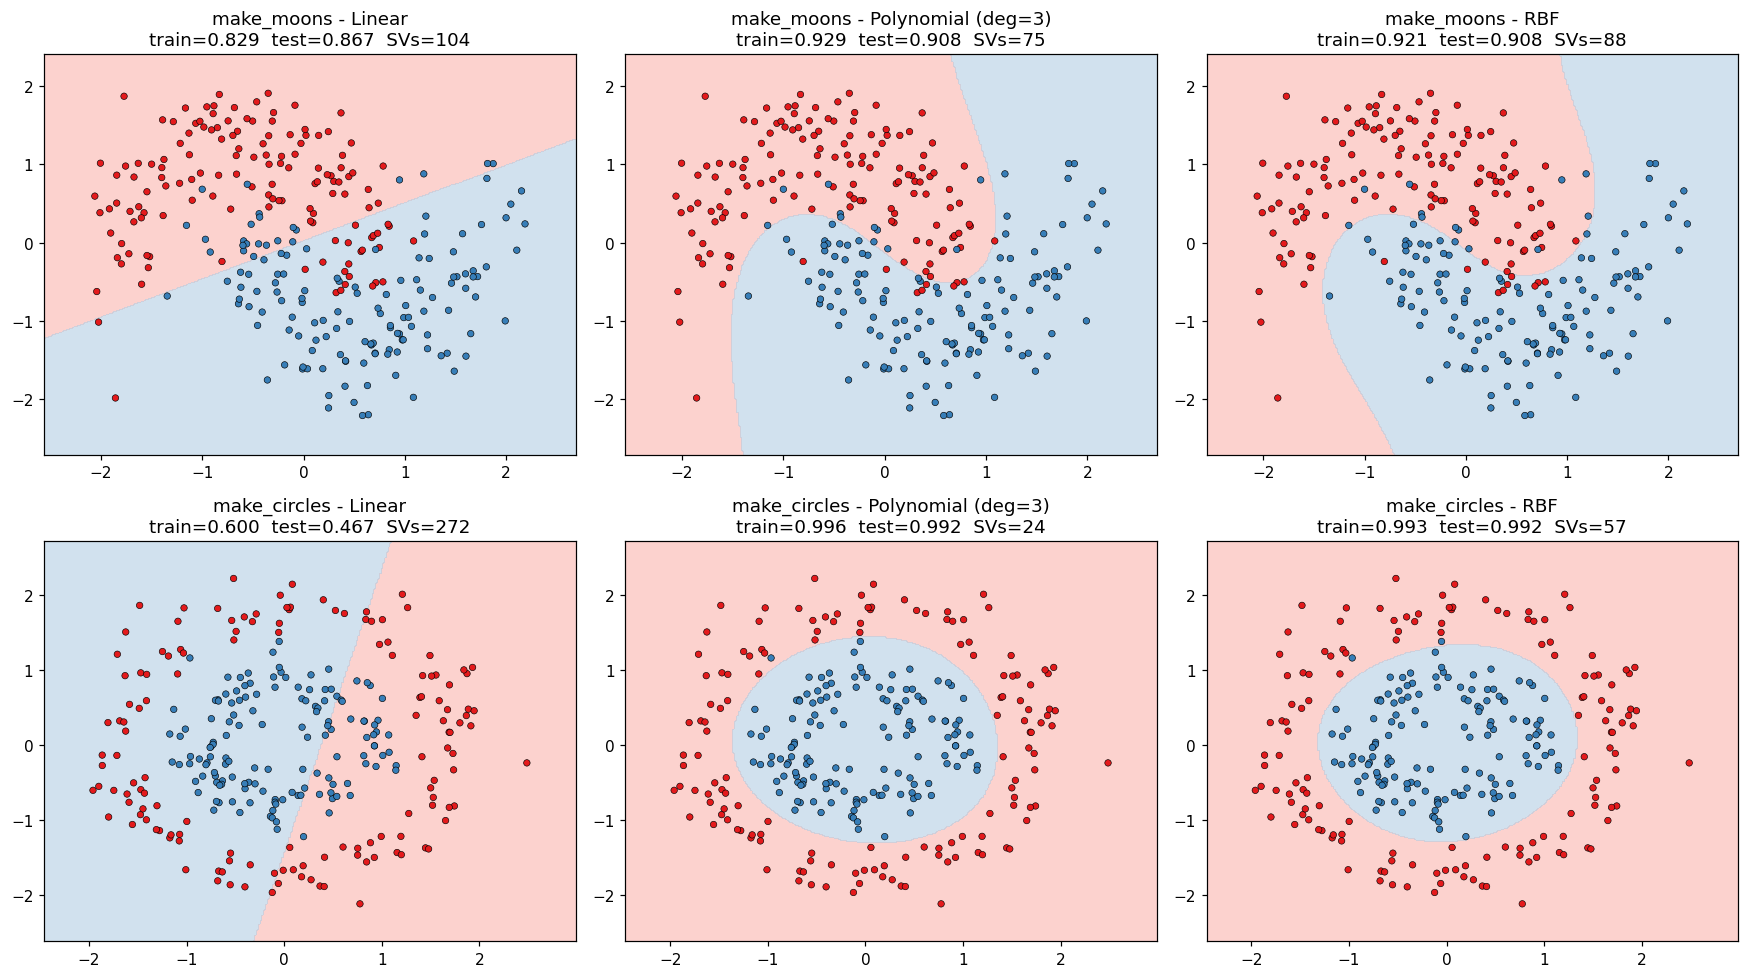

,dataset,kernel,train_acc,test_acc,n_support_vectors
0,make_moons,Linear,0.8286,0.8667,104
1,make_moons,Polynomial (deg=3),0.9286,0.9083,75
2,make_moons,RBF,0.9214,0.9083,88
3,make_circles,Linear,0.6000,0.4667,272
4,make_circles,Polynomial (deg=3),0.9964,0.9917,24
5,make_circles,RBF,0.9929,0.9917,57


In [13]:
datasets = {
    "make_moons":   make_moons(n_samples=400, noise=0.25, random_state=SEED),
    "make_circles": make_circles(n_samples=400, noise=0.12, factor=0.45, random_state=SEED),
}
kernels = {
    "Linear":              SVC(kernel="linear", C=1.0),
    "Polynomial (deg=3)":  SVC(kernel="poly", degree=3, coef0=1.0, gamma="scale", C=1.0),
    "RBF":                 SVC(kernel="rbf", gamma="scale", C=1.0),
}
fig, axes = plt.subplots(len(datasets), 3, figsize=(16, 9))
kernel_rows = []
for r, (dname, (Xd, yd)) in enumerate(datasets.items()):
    Xa, Xb, ya, yb = stratified_split(Xd, yd, 0.3, SEED)
    sc = StandardScalerScratch().fit(Xa); Xa_s, Xb_s = sc.transform(Xa), sc.transform(Xb)
    for c, (kname, model) in enumerate(kernels.items()):
        model.fit(Xa_s, ya)
        tr, te = accuracy_score(ya, model.predict(Xa_s)), accuracy_score(yb, model.predict(Xb_s))
        plot_boundary(model.predict, Xa_s, ya, axes[r, c], f"{dname} - {kname}\ntrain={tr:.3f}  test={te:.3f}  SVs={model.n_support_.sum()}")
        kernel_rows.append(dict(dataset=dname, kernel=kname, train_acc=tr, test_acc=te, n_support_vectors=int(model.n_support_.sum())))
plt.tight_layout(); plt.show()
display(pd.DataFrame(kernel_rows).round(4))

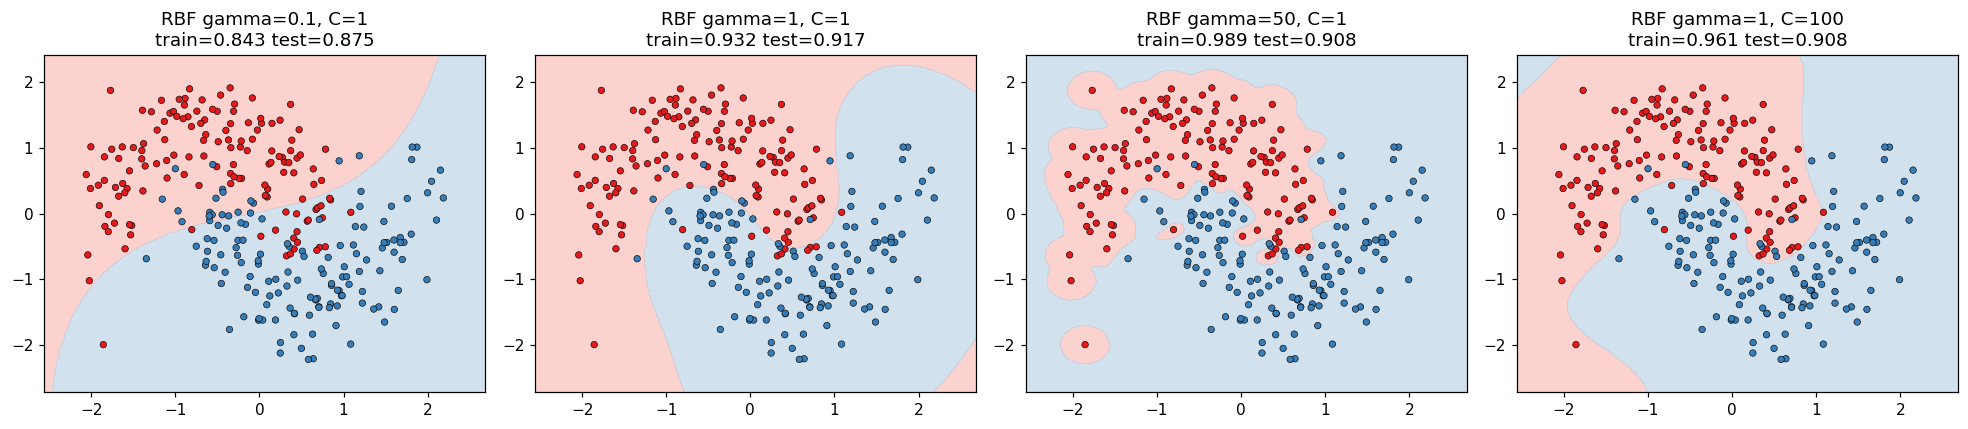

In [14]:
# RBF hyper-parameters on moons: gamma controls locality, C controls margin softness
Xd, yd = datasets["make_moons"]
Xa, Xb, ya, yb = stratified_split(Xd, yd, 0.3, SEED)
sc = StandardScalerScratch().fit(Xa); Xa_s, Xb_s = sc.transform(Xa), sc.transform(Xb)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (g, C) in zip(axes, [(0.1, 1), (1, 1), (50, 1), (1, 100)]):
    m = SVC(kernel="rbf", gamma=g, C=C).fit(Xa_s, ya)
    plot_boundary(m.predict, Xa_s, ya, ax, f"RBF gamma={g}, C={C}\ntrain={m.score(Xa_s, ya):.3f} test={m.score(Xb_s, yb):.3f}")
plt.tight_layout(); plt.show()

**Why a nonlinear kernel helps.** On `make_moons` / `make_circles` no straight line can separate the classes, so the linear SVM is stuck at a mediocre accuracy (for circles it is near chance).
The polynomial kernel adds interaction/curvature terms and can bend the boundary, but its global shape is rigid (and can extrapolate badly).
The RBF kernel builds a flexible, local boundary that follows the data's shape without choosing a polynomial degree; compare the test accuracies in the table (RBF and polynomial are usually close here, both far above linear).
Its flexibility must be controlled: large $\gamma$ or large $C$ gives islands around single points (overfitting), small $\gamma$ drifts toward a near-linear boundary (underfitting).


# Part D — Final comparison on the original Banknote data (all 4 features)


In [15]:
sc4 = StandardScalerScratch().fit(Xtr4)
Xtr4s, Xte4s = sc4.transform(Xtr4), sc4.transform(Xte4)

TREE_PARAMS = dict(criterion="gini", max_depth=5)
models = {
    "Manual Decision Tree":   (lambda: DecisionTreeScratch(**TREE_PARAMS),                      False, False),
    "Sklearn Decision Tree":  (lambda: DecisionTreeClassifier(**TREE_PARAMS, random_state=SEED), False, False),
    "Manual Linear SVM":      (lambda: LinearSVMScratch(C=1.0, lr=0.5, n_iters=2000, lr_decay=0.01), True, True),
    "Sklearn Linear SVM":     (lambda: SVC(kernel="linear", C=1.0),                              True, False),
    "Sklearn RBF SVM":        (lambda: SVC(kernel="rbf", C=1.0, gamma="scale"),                  True, False),
}   # (factory, needs_scaling, needs_pm1_labels)

def evaluate(name, factory, scaled, pm1, Xa, Xb, ya, yb, n_pred_repeats=20):
    Xa_, Xb_ = (sc4.transform(Xa), sc4.transform(Xb)) if scaled else (Xa, Xb)
    ya_fit = to_pm1(ya) if pm1 else ya
    model = factory()
    t0 = time.perf_counter(); model.fit(Xa_, ya_fit); fit_t = time.perf_counter() - t0
    t0 = time.perf_counter()
    for _ in range(n_pred_repeats): p = model.predict(Xb_)
    pred_t = (time.perf_counter() - t0) / n_pred_repeats
    p = from_pm1(p) if pm1 else p
    ptr = model.predict(Xa_); ptr = from_pm1(ptr) if pm1 else ptr
    return model, p, dict(model=name, train_acc=accuracy_score(ya, ptr), accuracy=accuracy_score(yb, p),
                          precision=precision_score(yb, p), recall=recall_score(yb, p), f1=f1_score(yb, p),
                          train_time_ms=fit_t * 1e3, predict_time_ms=pred_t * 1e3)

fitted, preds, rows = {}, {}, []
for name, (fac, scaled, pm1) in models.items():
    m, p, r = evaluate(name, fac, scaled, pm1, Xtr4, Xte4, ytr, yte)
    fitted[name], preds[name] = m, p; rows.append(r)
results = pd.DataFrame(rows).set_index("model")
display(results.round(4))

,train_acc,accuracy,precision,recall,f1,train_time_ms,predict_time_ms
model,,,,,,,
Manual Decision Tree,0.9863,0.9708,0.9750,0.959,0.9669,18.4481,0.5450
Sklearn Decision Tree,0.9863,0.9708,0.9750,0.959,0.9669,4.2506,0.1658
Manual Linear SVM,0.9854,0.9818,0.9606,1.000,0.9799,109.7285,0.0405
Sklearn Linear SVM,0.9854,0.9818,0.9606,1.000,0.9799,6.9798,0.5750
Sklearn RBF SVM,1.0000,1.0000,1.0000,1.000,1.0000,10.6280,2.8124


,model complexity
Manual Decision Tree,"depth=5, leaves=17"
Sklearn Decision Tree,"depth=5, leaves=17"
Manual Linear SVM,"5 parameters (w in R^4, b)"
Sklearn Linear SVM,5 parameters; 62 support vectors
Sklearn RBF SVM,91 support vectors (stores them for prediction)


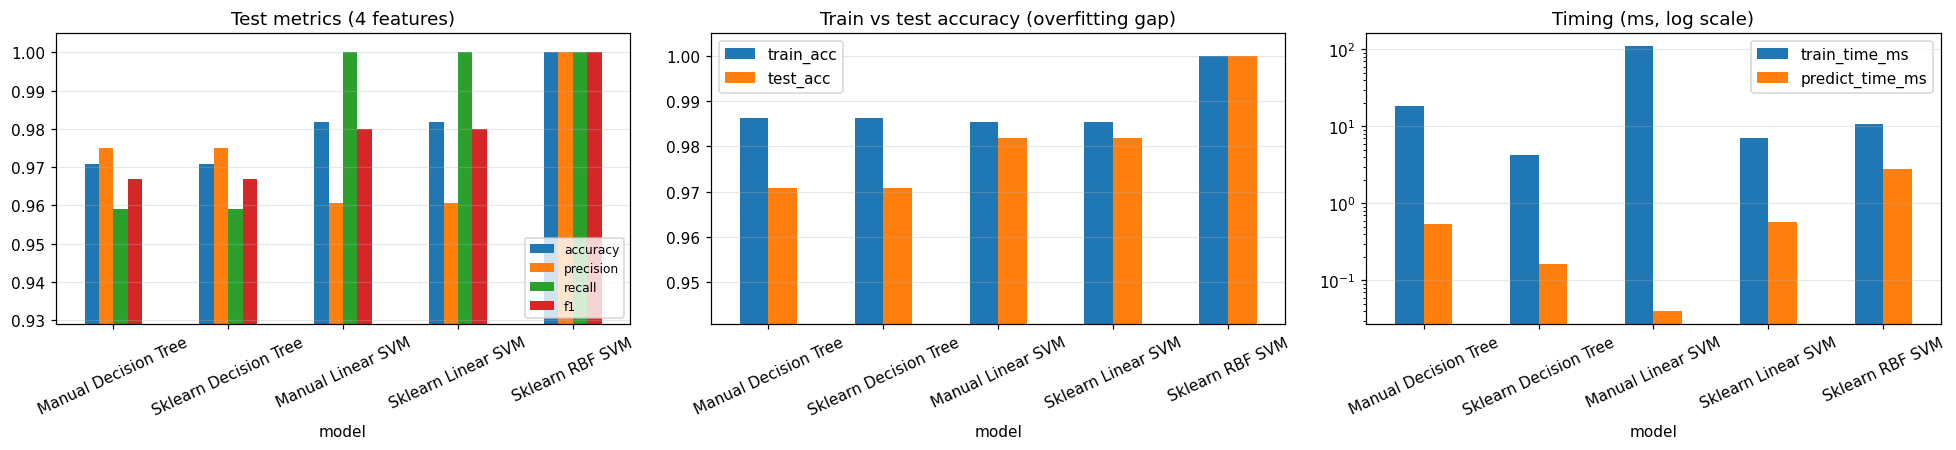

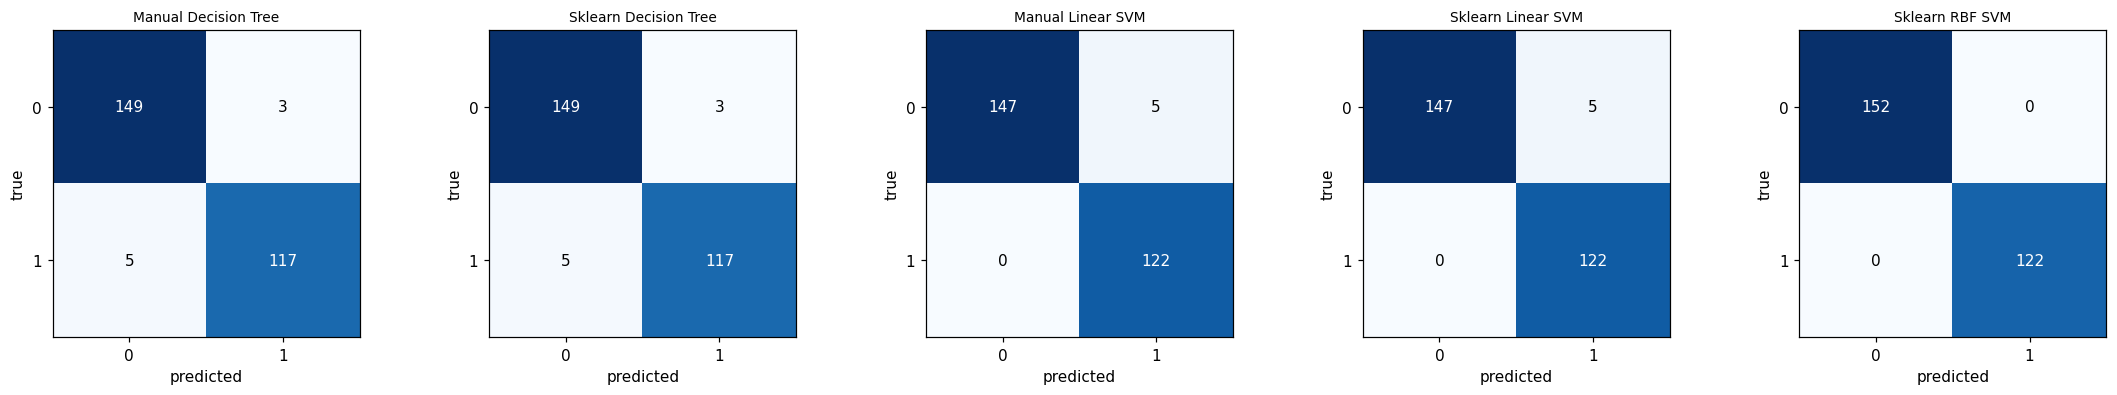

In [16]:
# complexity summary
cx = {
    "Manual Decision Tree":  f"depth={fitted['Manual Decision Tree'].get_depth()}, leaves={fitted['Manual Decision Tree'].get_n_leaves()}",
    "Sklearn Decision Tree": f"depth={fitted['Sklearn Decision Tree'].get_depth()}, leaves={fitted['Sklearn Decision Tree'].get_n_leaves()}",
    "Manual Linear SVM":     "5 parameters (w in R^4, b)",
    "Sklearn Linear SVM":    f"5 parameters; {fitted['Sklearn Linear SVM'].n_support_.sum()} support vectors",
    "Sklearn RBF SVM":       f"{fitted['Sklearn RBF SVM'].n_support_.sum()} support vectors (stores them for prediction)",
}
display(pd.DataFrame({"model complexity": cx}))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
results[["accuracy", "precision", "recall", "f1"]].plot.bar(ax=axes[0], rot=25, ylim=(max(0, results[["accuracy","precision","recall","f1"]].values.min() - 0.03), 1.005))
axes[0].set_title("Test metrics (4 features)"); axes[0].legend(loc="lower right", fontsize=8); axes[0].grid(axis="y", alpha=.3)
results[["train_acc", "accuracy"]].rename(columns={"accuracy": "test_acc"}).plot.bar(ax=axes[1], rot=25, ylim=(max(0, results[["train_acc","accuracy"]].values.min() - 0.03), 1.005))
axes[1].set_title("Train vs test accuracy (overfitting gap)"); axes[1].grid(axis="y", alpha=.3)
results[["train_time_ms", "predict_time_ms"]].plot.bar(ax=axes[2], rot=25, logy=True)
axes[2].set_title("Timing (ms, log scale)"); axes[2].grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(yte, p); ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max()/2 else "black")
    ax.set_title(name, fontsize=9); ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

###  Robustness: repeated stratified splits 

In [17]:
rep = {n: {"accuracy": [], "f1": []} for n in models}
for seed in range(10):
    Xa, Xb, ya, yb = stratified_split(X_all, y_all, 0.2, seed)
    sc4 = StandardScalerScratch().fit(Xa)           # re-fit scaler on each training fold (no leakage)
    for name, (fac, scaled, pm1) in models.items():
        _, _, r = evaluate(name, fac, scaled, pm1, Xa, Xb, ya, yb, n_pred_repeats=1)
        rep[name]["accuracy"].append(r["accuracy"]); rep[name]["f1"].append(r["f1"])
sc4 = StandardScalerScratch().fit(Xtr4)             # restore scaler for the main split
summary = pd.DataFrame({n: {"acc_mean": np.mean(v["accuracy"]), "acc_std": np.std(v["accuracy"]),
                            "f1_mean": np.mean(v["f1"]), "f1_std": np.std(v["f1"])} for n, v in rep.items()}).T
display(summary.round(4))

,acc_mean,acc_std,f1_mean,f1_std
Manual Decision Tree,0.9737,0.0074,0.9701,0.0087
Sklearn Decision Tree,0.9741,0.0077,0.9705,0.0090
Manual Linear SVM,0.9876,0.0066,0.9863,0.0071
Sklearn Linear SVM,0.9872,0.0064,0.9859,0.0069
Sklearn RBF SVM,1.0000,0.0000,1.0000,0.0000


In [18]:
# Auto-generated summary of the main-split results
best = lambda col, asc=False: results[col].idxmin() if asc else results[col].idxmax()
print(f"Best accuracy : {best('accuracy')} ({results['accuracy'].max():.4f})")
print(f"Best F1       : {best('f1')} ({results['f1'].max():.4f})")
print(f"Fastest train : {best('train_time_ms', True)} ({results['train_time_ms'].min():.2f} ms)")
print(f"Fastest predict: {best('predict_time_ms', True)} ({results['predict_time_ms'].min():.3f} ms)")
gap = (results['train_acc'] - results['accuracy']).sort_values(ascending=False)
print("Largest train-test gap:", gap.index[0], f"({gap.iloc[0]:+.4f})")

Best accuracy : Sklearn RBF SVM (1.0000)
Best F1       : Sklearn RBF SVM (1.0000)
Fastest train : Sklearn Decision Tree (4.25 ms)
Fastest predict: Manual Linear SVM (0.041 ms)
Largest train-test gap: Manual Decision Tree (+0.0155)




**Accuracy / precision / recall / F1.** Banknote authentication is an almost linearly separable problem in the four wavelet features, so all models score high.
The RBF SVM can model the mildly curved class boundary and typically comes out on top (≈ 100 % on this dataset); the tree and the linear SVM are close behind.
Precision and recall are both reported because errors are asymmetric in practice (accepting a forged note vs rejecting a genuine one); the confusion matrices show which kind of error each model makes.
The manual models should track their scikit-learn counterparts closely, confirming the implementations are correct.

**Interpretability.** The tree is the most transparent: every prediction is a short chain of `feature <= threshold` rules that can be read from the printed rules / tree plot.
The linear SVM is interpretable through its weight vector (sign and size of each scaled weight show feature influence). The RBF SVM is a black box — its decision depends on many support vectors.

**Scaling.** Trees are invariant to monotone feature scaling (splits compare one feature to a threshold). SVMs are not: the margin and RBF distance depend on feature scales, so features must be standardised using
training statistics only (done here, to avoid leakage). Gradient descent also converges much faster on scaled features.

**Overfitting and complexity.** An unrestricted tree can reach 100 % training accuracy by memorising points, so depth (or min-samples / min-impurity-decrease) must be controlled — see Part A.
The linear SVM has only 5 parameters, so it has low variance but high bias if the data were nonlinear (Part C). The RBF SVM is the most flexible; `C` and `gamma` control overfitting, and its model size grows with the number of support vectors.
Train-vs-test gaps in the bar plot quantify this.

**Speed.** The from-scratch tree and SVM are pure NumPy/Python so they train slower than the optimised C implementations in scikit-learn; prediction for trees and linear SVMs is very cheap,
while the RBF SVM must evaluate the kernel against every support vector at prediction time. Exact numbers are in the timing table (they vary by machine).

**Takeaway.** Use a tree when interpretability matters, a linear SVM for a fast, compact and robust baseline on scaled data, and an RBF SVM when the boundary is nonlinear and accuracy matters most.